# Covariate-adjusted perturbation effects on a genome-scale CD4+ T-cell screen

A perturbation's cells and the control cells rarely come from the same mix of donors, 10x lanes and
sequencing depths. A plain target-versus-control comparison reads those differences as perturbation
effects. `cx.tl.residual_effects` implements the estimator of Feng et al. (2025, *Cell Genomics*):

1. normalise every cell to `log1p` counts per 10,000;
2. regress each gene on the covariates **over the control cells only**, by ordinary least squares;
3. a perturbation's effect is the mean, over its cells, of observed minus predicted expression,
   tested against a residual spread.

crispyx does this in **one streaming pass** over the raw counts: it collects per-perturbation sums and
the controls' cross-products, then solves a small least-squares problem. No per-cell residual is
stored and the matrix is never loaded.

**Data.** The resting-state CD4+ T cells of three donors (D1–D3) from the genome-scale CRISPRi
Perturb-seq of Zhu, Dann, Marson *et al.* (bioRxiv 2025): 5.6 million cells, 18,130 genes, 21.5 billion
non-zero counts, 12,500 knocked-down genes. The authors published their own estimates (DESeq2 on donor x
guide pseudo-bulk), for all donors together and for every pair of donors.

The notebook has two parts:

- **Part 1 — comparison with the paper.** Effects from D1–D3 against the authors' four-donor results,
  for three choices of covariates.
- **Part 2 — validation on a held-out donor.** Both methods fitted on the same two donors, judged on a
  donor neither has seen; then why the two disagree where they do.

The whole notebook is meant to run within 3 hours on 32 cores with 256 GB of memory; it was executed on
a 32-core workstation, and the table at the end lists the wall time and peak memory of every step.

In [1]:
import os
import sys
import warnings
from contextlib import contextmanager
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Paths stay relative to this notebook's directory so that the paths crispyx
# echoes in its output are the same on every machine.
ROOT = Path('../..')
sys.path.insert(0, str(ROOT / 'src'))
# Progress bars off, so the saved notebook keeps only crispyx's summary lines.
os.environ.setdefault('TQDM_DISABLE', '1')
warnings.filterwarnings('ignore', message='IProgress not found')
import crispyx as cx

DATA_DIR = ROOT / 'data' / 'gwcd4i'
OUTPUT_DIR = Path('tutorial_outputs')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
DONORS = ['D1', 'D2', 'D3']

cores = len(os.sched_getaffinity(0)) if hasattr(os, 'sched_getaffinity') else os.cpu_count()
print(f'crispyx {cx.__version__}, {cores} cores')

steps = []


@contextmanager
def measured(step):
    # record a step's wall time and this process's peak memory while it runs
    with cx.Profiler(timing=True, sampling=True, memory_method='rss', sample_interval=0.5) as profiler:
        yield
    stats = profiler.get_stats()
    minutes = stats['timing']['total_seconds'] / 60
    peak_gb = stats['memory']['peak_mb'] / 1024
    steps.append({'step': step, 'wall time (min)': round(minutes, 1), 'peak RSS (GB)': round(peak_gb, 1)})
    print(f'{step}: {minutes:.1f} min, peak RSS {peak_gb:.1f} GB')


@contextmanager
def warnings_as_messages():
    # print crispyx's warnings by message only: the default banner names the source file
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        warnings.simplefilter('ignore', DeprecationWarning)
        yield
    for message in dict.fromkeys(f'{w.category.__name__}: {w.message}' for w in caught):
        print(message)

crispyx 0.1.10, 32 cores


## Get the data

The files are public (MIT licence) in the S3 bucket `genome-scale-tcell-perturb-seq`; no account is
needed. Each donor's resting-state file holds every captured cell, 138–143 GB of raw counts. Run once,
from the repository root (this cell is not executed here):

```bash
mkdir -p data/gwcd4i && cd data/gwcd4i
BUCKET=https://genome-scale-tcell-perturb-seq.s3.amazonaws.com/marson2025_data
for donor in D1 D2 D3; do curl -O "$BUCKET/${donor}_Rest.assigned_guide.h5ad"; done
curl -O "$BUCKET/GWCD4i.DE_stats.h5ad"             # the authors' DE results, 16.8 GB
curl -O "$BUCKET/GWCD4i.DE_stats.by_donors.h5mu"   # the same per pair of donors, 16.9 GB
```

# Part 1 — Comparison with the paper

## 1. Keep the guide-resolved cells, on disk

Each file also contains cells without a detected guide, cells with several guides and cells flagged as
low quality. `cx.write_filtered_subset` streams one file to a new one, keeping the rows of a boolean
mask; row chunks without a kept cell are not read. The mask comes from `obs` alone, read with
`cx.load_obs` without touching the matrix.

In [2]:
filtered = {}
with measured('keep guide-resolved cells (3 files)'):
    for donor in DONORS:
        source = DATA_DIR / f'{donor}_Rest.assigned_guide.h5ad'
        obs = cx.load_obs(source)
        keep = (
            obs['guide_type'].eq('non-targeting')
            | (obs['guide_type'].eq('targeting') & obs['perturbed_gene_name'].notna())
        ) & ~obs['low_quality'].astype(bool)
        filtered[donor] = OUTPUT_DIR / f'{donor}.h5ad'
        with warnings_as_messages():
            cx.write_filtered_subset(
                source,
                cell_mask=keep.to_numpy(),
                gene_mask=np.ones(len(cx.load_var(source)), dtype=bool),
                output_path=filtered[donor],
            )
        print(f'{donor}: kept {keep.sum():,} of {len(obs):,} cells')

D1: kept 1,752,037 of 3,074,496 cells
D2: kept 1,983,457 of 2,940,194 cells
D3: kept 1,901,710 of 2,778,524 cells
keep guide-resolved cells (3 files): 7.2 min, peak RSS 6.9 GB


## 2. Concatenate the donors, on disk

`cx.pp.concat_h5ad` writes the three files into one CSR matrix, streaming each file in row chunks.
`label='donor'` records each cell's source file (its stem) in `obs['donor']`. The barcodes carry a
sample suffix, so no cell occurs in two files; `shared_cells='error'` makes the call check that
instead of assuming it.

The files do not list their genes in the same order: D3's columns are a permutation of D1's. Genes are
matched by name, so each column of the output means the same gene for every cell. Stacking the
matrices as they are would silently relabel all of D3's genes.

In [3]:
merged_path = OUTPUT_DIR / 'CD4T_Rest_D1-D3.h5ad'
gene_order = {donor: list(cx.load_var(filtered[donor]).index) for donor in DONORS}
print('same gene order as D1:', {donor: gene_order[donor] == gene_order['D1'] for donor in DONORS})
with measured('concatenate the donors'), warnings_as_messages():
    merged = cx.pp.concat_h5ad(
        [filtered[donor] for donor in DONORS],
        output_path=merged_path, label='donor', shared_cells='error',
    )
merged

same gene order as D1: {'D1': True, 'D2': True, 'D3': False}
[cx] pp.concat_h5ad: Done  5637204 cells × 18130 genes
[cx] pp.concat_h5ad: Saving → tutorial_outputs/CD4T_Rest_D1-D3.h5ad
concatenate the donors: 4.2 min, peak RSS 9.0 GB


AnnData(path=tutorial_outputs/CD4T_Rest_D1-D3.h5ad, mode='r')

## 3. Labels and covariates

The perturbation label is the targeted gene, or `non-targeting` for the controls. It is passed as a
`pd.Series` indexed by cell, so nothing is written back into the file; a cell whose label is NaN is not
used, which is how part 2 restricts the fit to some donors.

`covariates` has no default. Adjust for what describes how a cell was processed — donor and 10x lane
here — which no perturbation changes. Sequencing depth and mitochondrial share are also available
(`log_total_counts` and `mito_fraction`, computed from the counts during the pass), but many knockdowns
change them, and regressing them out then removes part of the effect; part 1 runs both designs and
part 2 measures the difference.

Lanes are shared between donors: the first 10x run (lanes `CD4i_R1L..`) holds donors D1 and D2, the
second (`CD4i_R2L..`) donors D3 and D4. With D4 left out, the second run's lanes contain only D3, so
the donor and lane columns overlap; `residual_effects` notes that the design is rank deficient, which
leaves the fitted values and the effects unchanged.

In [4]:
obs = cx.load_obs(merged_path)
labels = (
    obs['perturbed_gene_name'].astype(object)
    .where(obs['guide_type'].ne('non-targeting'), 'non-targeting')
    .rename('perturbation')
)
print(f'{len(obs):,} cells, {labels.nunique() - 1:,} targeted genes, '
      f"{(labels == 'non-targeting').sum():,} control cells")
pd.crosstab(obs['lane_id'].str[:7].rename('10x run'), obs['donor'])

5,637,204 cells, 12,511 targeted genes, 237,353 control cells


donor,D1,D2,D3
10x run,,,
CD4i_R1,1752037,1983457,0
CD4i_R2,0,0,1901710


## 4. Effects for three designs

The main design adjusts for donor and lane. For comparison: the same plus depth and mitochondrial
share (the covariates of Feng et al.), and no covariates (each perturbation's mean minus the
controls').

`null='robust'` divides each effect by 1.4826 x the median absolute deviation of `effect * sqrt(n)`
across perturbations rather than by the control fit's residual spread (`null='model'`). The model
null treats cells as independent; cells sharing a guide or a donor are not, which makes it
anti-conservative. The robust null suits genome-wide screens, where most perturbations leave a given
gene unchanged. Both spreads are written to `var`, so the other z-score needs no second pass.

In [5]:
designs = {
    'donor + lane': ['donor', 'lane_id'],
    'donor + lane + depth + mito': ['donor', 'lane_id', 'log_total_counts', 'mito_fraction'],
    'no covariates': [],
}
results = {}
for name, covariates in designs.items():
    with measured(f'residual_effects, {name}'):
        results[name] = cx.tl.residual_effects(
            merged_path, labels, 'non-targeting',
            covariates=covariates, null='robust', gene_name_column='gene_name',
            output_path=OUTPUT_DIR / f"cd4t_{name.replace(' + ', '_').replace(' ', '_')}.h5ad",
        )
results['donor + lane']

[cx] residual_effects: Reading tutorial_outputs/CD4T_Rest_D1-D3.h5ad
[cx] residual_effects: 506 perturbation(s) have fewer than 10 cells and are left out: ['NOL10', 'DNA2', 'PNO1', 'AMMECR1L', 'ABCF1', 'SMC3', 'PI4KA', 'C19orf25', 'GOLT1B', 'GUCA2B']
[cx] residual_effects: 12,005 perturbations, 237,353 control cells, design: 49 columns
[cx] residual_effects: the design has rank 48 < 49 columns (collinear covariates); fitted values and effects are still unique.
[cx] residual_effects: estimated disk usage: 7.7 GB (2.6 TB free)
[cx] residual_effects: 12,005 perturbations x 18,130 genes (7,975 tested), robust null
[cx] residual_effects: Saving → tutorial_outputs/cd4t_donor_lane.h5ad
residual_effects, donor + lane: 1.3 min, peak RSS 16.1 GB
[cx] residual_effects: Reading tutorial_outputs/CD4T_Rest_D1-D3.h5ad
[cx] residual_effects: 506 perturbation(s) have fewer than 10 cells and are left out: ['NOL10', 'DNA2', 'PNO1', 'AMMECR1L', 'ABCF1', 'SMC3', 'PI4KA', 'C19orf25', 'GOLT1B', 'GUCA2B']
[cx

AnnData(path=tutorial_outputs/cd4t_donor_lane.h5ad, mode='r')

`X` holds the effect: a difference of mean `log1p(CP10k)` values (natural log), **not** a log2 fold
change. `z_score`, `pvalue` and `pvalue_adj` (Benjamini–Hochberg within each perturbation) are
layers; `var` holds the control mean, the two spreads and which genes were tested (control mean above
0.1, as in Feng et al.).

In [6]:
results['donor + lane'].backed.var.head()

,control_mean,residual_sd,robust_sd,tested
gene_name,,,,
TSPAN6,0.000060,0.006828,0.000523,False
TNMD,0.000003,0.001448,0.000055,False
DPM1,0.801106,0.603089,0.749118,True
SCYL3,0.264869,0.432735,0.453073,True
C1orf112,0.385325,0.552520,0.883691,True


In [7]:
def load_effects(result):
    # effect, z under both nulls, cells per perturbation and gene table of a result
    with h5py.File(result.path, 'r') as handle:
        effect = handle['X'][:]
        padj = handle['layers/pvalue_adj'][:]
    backed = result.backed
    var = backed.var
    n_cells = backed.obs['n_cells'].to_numpy()
    tested = var['tested'].to_numpy()
    out = {'targets': pd.Index(backed.obs_names), 'genes': pd.Index(backed.var_names),
           'effect': effect, 'padj': padj, 'n_cells': n_cells, 'var': var}
    for null, column in (('model', 'residual_sd'), ('robust', 'robust_sd')):
        spread = var[column].to_numpy()
        usable = tested & (spread > 0)
        z = np.full_like(effect, np.nan)
        z[:, usable] = effect[:, usable] * np.sqrt(n_cells)[:, None] / spread[usable]
        out[f'z_{null}'] = z
    return out


def column(group, key):
    # one obs/var column of an h5ad (or h5mu modality) group, decoding categoricals
    item = group[key]
    if isinstance(item, h5py.Group):
        return item['categories'][:].astype(str)[item['codes'][:]]
    values = item[:]
    return values.astype(str) if values.dtype.kind in 'SO' else values


def paper_table(path, modality=None, meta_columns=()):
    # resting-state rows of the authors' DESeq2 results (whole table, or one donor-pair modality)
    with h5py.File(path, 'r') as handle:
        group = handle if modality is None else handle['mod'][modality]
        names = column(group['obs'], 'target_contrast_gene_name')
        rows = np.flatnonzero(column(group['obs'], 'culture_condition') == 'Rest')
        rows = rows[~pd.Index(names[rows]).duplicated(keep=False)]
        # dense, uncompressed layers: one sequential read each, then the rows we need
        table = {name: group['layers'][name][:][rows] for name in ('zscore', 'log_fc', 'adj_p_value')}
        table['meta'] = pd.DataFrame({c: column(group['obs'], c)[rows] for c in meta_columns}, index=names[rows])
        table['targets'] = pd.Index(names[rows])
        table['genes'] = pd.Index(column(group['var'], 'gene_name'))
    return table


def on(source_targets, source_genes, matrix, targets, genes):
    # rows and columns of matrix for the given targets and genes
    return matrix[source_targets.get_indexer(targets)][:, source_genes.get_indexer(genes)]


def per_target_r(a, b):
    # Pearson r of each row of a with the same row of b, over genes finite in both
    ok = np.isfinite(a) & np.isfinite(b)
    n = np.maximum(ok.sum(axis=1, keepdims=True), 1)
    a = np.where(ok, a, 0.0)
    b = np.where(ok, b, 0.0)
    a = np.where(ok, a - a.sum(axis=1, keepdims=True) / n, 0.0)
    b = np.where(ok, b - b.sum(axis=1, keepdims=True) / n, 0.0)
    return (a * b).sum(axis=1) / np.sqrt((a * a).sum(axis=1) * (b * b).sum(axis=1))


effects = {name: load_effects(result) for name, result in results.items()}
main = effects['donor + lane']
print(f"{len(main['targets']):,} perturbations x {len(main['genes']):,} genes, "
      f"{int(main['var']['tested'].sum()):,} tested; robust / model spread at the median gene: "
      f"{np.nanmedian(main['var']['robust_sd'] / main['var']['residual_sd']):.2f}")

12,005 perturbations x 18,130 genes, 7,975 tested; robust / model spread at the median gene: 1.07


## 5. Compare with the authors' estimates

`GWCD4i.DE_stats.h5ad` holds the authors' DESeq2 results for every target and culture condition
(guide x donor pseudo-bulk sums, all four donors). Only the resting-state targets we share are used;
targets and genes are matched by symbol.

The two estimates are on different scales — theirs a DESeq2 log2 fold change of pseudo-bulk sums,
ours a difference of mean `log1p(CP10k)` — so the comparison is of z-scores and directions per
target, not of values. Under a correct null, 0.27% of genes reach |z| > 3; the paper's non-hits are not
all true nulls (four-donor pseudo-bulk DESeq2 is conservative), so that column is an upper bound on
miscalibration.

In [8]:
paper = paper_table(
    DATA_DIR / 'GWCD4i.DE_stats.h5ad',
    meta_columns=('n_total_de_genes', 'n_cells_target', 'ontarget_significant', 'low_target_gex',
                  'distal_offtarget_flag', 'donor_correlation_all_mean'),
)
targets = paper['targets'].intersection(main['targets'])
genes = paper['genes'].intersection(main['genes'][main['var']['tested'].to_numpy()])
paper_z = on(paper['targets'], paper['genes'], paper['zscore'], targets, genes)
paper_q = on(paper['targets'], paper['genes'], paper['adj_p_value'], targets, genes)
paper_meta = paper['meta'].loc[targets]
strong = paper_meta['n_total_de_genes'].astype(float).to_numpy() >= 10
hits = paper_q < 0.1
non_hits = (paper_q >= 0.1) & np.isfinite(paper_z)
print(f'{len(targets):,} shared targets ({strong.sum():,} with >= 10 DE genes in the paper), '
      f'{len(genes):,} shared tested genes, {hits.sum():,} paper hits')

comparison, per_target = [], {}
for name, est in effects.items():
    for null in ('robust', 'model'):
        z = on(est['targets'], est['genes'], est[f'z_{null}'], targets, genes)
        r = per_target_r(z, paper_z)
        per_target[name, null] = r
        ok = hits & np.isfinite(z)
        comparison.append({
            'design': name, 'null': null,
            'median r(z), all targets': np.nanmedian(r),
            'median r(z), >= 10 paper DE genes': np.nanmedian(r[strong]),
            "sign agreement on the paper's hits": np.mean(np.sign(z[ok]) == np.sign(paper_z[ok])),
            "|z| > 3 among the paper's non-hits": np.mean(np.abs(z[non_hits & np.isfinite(z)]) > 3),
        })
pd.DataFrame(comparison).set_index(['design', 'null']).round(3)

10,969 shared targets (2,491 with >= 10 DE genes in the paper), 7,385 shared tested genes, 513,577 paper hits


median r(z), all targets  \
design                      null                               
donor + lane                robust                     0.729   
                            model                      0.693   
donor + lane + depth + mito robust                     0.707   
                            model                      0.671   
no covariates               robust                     0.684   
                            model                      0.635   

                                    median r(z), >= 10 paper DE genes  \
design                      null                                        
donor + lane                robust                              0.766   
                            model                               0.737   
donor + lane + depth + mito robust                              0.728   
                            model                               0.700   
no covariates               robust                              0.729   
                            model                               0.692   

                                    sign agreement on the paper's hits  \
design                      null                                         
donor + lane                robust                               0.977   
                            model                                0.977   
donor + lane + depth + mito robust                               0.959   
                            model                                0.959   
no covariates               robust                               0.969   
                            model                                0.969   

                                    |z| > 3 among the paper's non-hits  
design                      null                                        
donor + lane                robust                               0.010  
                            model                                0.047  
donor + lane + depth + mito robust                               0.010  
                            model                                0.041  
no covariates               robust                               0.011  
                            model                                0.067

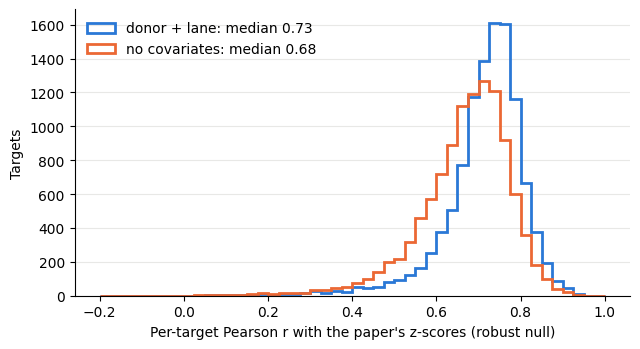

In [9]:
ADJUSTED, UNADJUSTED = '#2a78d6', '#eb6834'
fig, ax = plt.subplots(figsize=(6.5, 3.6))
bins = np.linspace(-0.2, 1.0, 49)
for name, color in (('donor + lane', ADJUSTED), ('no covariates', UNADJUSTED)):
    r = per_target[name, 'robust']
    ax.hist(r[np.isfinite(r)], bins=bins, histtype='step', linewidth=2, color=color,
            label=f'{name}: median {np.nanmedian(r):.2f}')
ax.set_xlabel("Per-target Pearson r with the paper's z-scores (robust null)")
ax.set_ylabel('Targets')
ax.legend(frameon=False, loc='upper left')
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)
ax.grid(axis='y', color='#e8e8e6', linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()

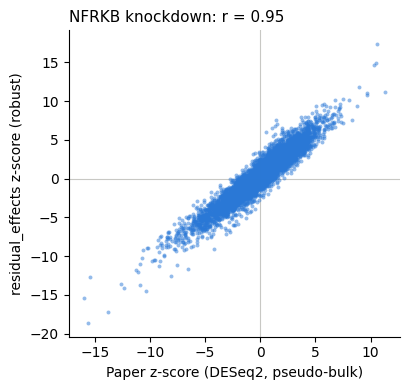

In [10]:
main_z = on(main['targets'], main['genes'], main['z_robust'], targets, genes)
r_main = per_target['donor + lane', 'robust']
example = targets[np.argmax(np.where(strong, np.nan_to_num(r_main, nan=-1), -np.inf))]
i = targets.get_loc(example)
fig, ax = plt.subplots(figsize=(4.2, 4.0))
ax.scatter(paper_z[i], main_z[i], s=8, color=ADJUSTED, alpha=0.5, linewidths=0)
ax.axhline(0, color='#c8c8c4', linewidth=0.8, zorder=0)
ax.axvline(0, color='#c8c8c4', linewidth=0.8, zorder=0)
ax.set_xlabel('Paper z-score (DESeq2, pseudo-bulk)')
ax.set_ylabel('residual_effects z-score (robust)')
ax.set_title(f'{example} knockdown: r = {r_main[i]:.2f}', loc='left', fontsize=11)
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)
plt.tight_layout()

The knocked-down gene itself should go down. Among targets whose gene is measured and tested:

In [11]:
own = main['genes'].get_indexer(main['targets'])
measured_own = (own >= 0) & main['var']['tested'].to_numpy()[np.maximum(own, 0)]
own_effect = main['effect'][np.flatnonzero(measured_own), own[measured_own]]
print(f'{measured_own.sum():,} targets: own-gene effect negative for {np.mean(own_effect < 0):.1%}, '
      f'median {np.median(own_effect):.2f} (log1p CP10k)')

7,090 targets: own-gene effect negative for 97.5%, median -0.26 (log1p CP10k)


# Part 2 — Validation on a held-out donor

Agreement with the paper says how close two methods are, not which is right. To compare them on equal
terms, both are fitted on the **same two donors, D1 and D2**: `residual_effects` (donor + lane, robust
null) on our file, and the authors' DESeq2 fit on that pair, which they published in
`GWCD4i.DE_stats.by_donors.h5mu` (donor IDs from their sample table: D1 = CE0008162, D2 = CE0010866,
D3 = CE0008678, D4 = CE0006864). Both are then judged on **D3**, a donor neither has seen, sequenced
in a different 10x run.

There is no method-free truth, so three held-out estimates are used, each biased differently:

- **A** — D3 by `residual_effects` (lane, robust null): our method, so it may favour ours;
- **B** — D3 with no covariates (plain difference of means from the controls), the least modelled;
- **C** — the authors' DESeq2 fit on D3 + D4: their pipeline, so it may favour theirs.

In [12]:
held_out = {  # name: (donors, covariates, output file)
    'fit on D1+D2': (['D1', 'D2'], ['donor', 'lane_id'], 'heldout_fit_D1D2.h5ad'),
    'truth A: D3, lane': (['D3'], ['lane_id'], 'heldout_truth_A_D3.h5ad'),
    'truth B: D3, no covariates': (['D3'], [], 'heldout_truth_B_D3.h5ad'),
}
validation = {}
for name, (donors, covariates, filename) in held_out.items():
    with measured(f'residual_effects, {name}'):
        validation[name] = load_effects(cx.tl.residual_effects(
            merged_path, labels.where(obs['donor'].isin(donors)), 'non-targeting',
            covariates=covariates, null='robust', gene_name_column='gene_name', min_cells=5,
            output_path=OUTPUT_DIR / filename, verbose=0,
        ))

pairs = DATA_DIR / 'GWCD4i.DE_stats.by_donors.h5mu'
paper_d12 = paper_table(pairs, 'CE0008162_CE0010866')
paper_d34 = paper_table(pairs, 'CE0006864_CE0008678')

ours_d12 = validation['fit on D1+D2']
T = ours_d12['targets']
for table in (paper_d12, paper_d34, validation['truth A: D3, lane'], validation['truth B: D3, no covariates']):
    T = T.intersection(table['targets'])
G = ours_d12['genes'][ours_d12['var']['tested'].to_numpy()].intersection(paper_d12['genes'])
G = G.intersection(paper_d34['genes'])
fits = {
    'residual_effects (D1+D2)': (on(ours_d12['targets'], ours_d12['genes'], ours_d12['z_robust'], T, G),
                                 on(ours_d12['targets'], ours_d12['genes'], ours_d12['padj'], T, G)),
    'paper DESeq2 (D1+D2)': (on(paper_d12['targets'], paper_d12['genes'], paper_d12['zscore'], T, G),
                             on(paper_d12['targets'], paper_d12['genes'], paper_d12['adj_p_value'], T, G)),
}
truths = {
    'A': on(validation['truth A: D3, lane']['targets'], validation['truth A: D3, lane']['genes'],
            validation['truth A: D3, lane']['z_robust'], T, G),
    'B': on(validation['truth B: D3, no covariates']['targets'], validation['truth B: D3, no covariates']['genes'],
            validation['truth B: D3, no covariates']['z_robust'], T, G),
    'C': on(paper_d34['targets'], paper_d34['genes'], paper_d34['zscore'], T, G),
}
print(f'{len(T):,} targets in every table (the pair tables keep only targets testable within the pair), '
      f'{len(G):,} genes')

residual_effects, fit on D1+D2: 0.8 min, peak RSS 58.6 GB
residual_effects, truth A: D3, lane: 0.6 min, peak RSS 64.8 GB
residual_effects, truth B: D3, no covariates: 0.6 min, peak RSS 70.1 GB
1,474 targets in every table (the pair tables keep only targets testable within the pair), 7,354 genes


### Agreement and replication

For each fit: its per-target correlation with each held-out estimate, how many hits it calls
(BH-adjusted p < 0.1), and how often a hit **replicates** — the held-out estimate has the same sign,
and (stricter) the same sign with |z| > 2. Because the two methods call very different numbers of hits,
the last block compares them at **equal calls**: for every target, each method's top *k* genes by |z|,
with *k* the number of hits the paper's fit calls for that target.

In [13]:
def replication(calls, z):
    row = {}
    for name, truth in truths.items():
        ok = calls & np.isfinite(truth)
        same = np.sign(z[ok]) == np.sign(truth[ok])
        row[f'{name}: same sign'] = same.mean()
        row[f'{name}: same sign, |z|>2'] = (same & (np.abs(truth[ok]) > 2)).mean()
    return row


k = ((fits['paper DESeq2 (D1+D2)'][1] < 0.1) & np.isfinite(fits['paper DESeq2 (D1+D2)'][0])).sum(axis=1)
rows = []
for name, (z, q) in fits.items():
    agreement = {f'{t}: median r': np.nanmedian(per_target_r(z, truth)) for t, truth in truths.items()}
    calls = (q < 0.1) & np.isfinite(z)
    rows.append({'fit': name, 'calls': 'hits (BH < 0.1)', 'n': calls.sum(), **agreement, **replication(calls, z)})
    score = np.where(np.isfinite(z), np.abs(z), -1)
    order = np.argsort(-score, axis=1)
    top = np.zeros_like(calls)
    for i in range(len(T)):
        top[i, order[i, :k[i]]] = True
    top &= score >= 0
    rows.append({'fit': name, 'calls': 'top k per target', 'n': top.sum(), **agreement, **replication(top, z)})
pd.DataFrame(rows).set_index(['fit', 'calls']).round(3).T

fit                 residual_effects (D1+D2)                   \
calls                        hits (BH < 0.1) top k per target   
n                                 475683.000       221246.000   
A: median r                            0.116            0.116   
B: median r                            0.117            0.117   
C: median r                            0.159            0.159   
A: same sign                           0.624            0.701   
A: same sign, |z|>2                    0.119            0.186   
B: same sign                           0.624            0.701   
B: same sign, |z|>2                    0.119            0.186   
C: same sign                           0.646            0.738   
C: same sign, |z|>2                    0.146            0.265   

fit                 paper DESeq2 (D1+D2)                   
calls                    hits (BH < 0.1) top k per target  
n                             221246.000       221246.000  
A: median r                        0.124            0.124  
B: median r                        0.124            0.124  
C: median r                        0.183            0.183  
A: same sign                       0.698            0.698  
A: same sign, |z|>2                0.177            0.178  
B: same sign                       0.698            0.698  
B: same sign, |z|>2                0.177            0.178  
C: same sign                       0.786            0.785  
C: same sign, |z|>2                0.308            0.308

### Where the two fits disagree, which side does the held-out donor take?

Only pairs where the held-out estimate is itself clear (|z| > 2) are counted.

In [14]:
ours_z, ours_q = fits['residual_effects (D1+D2)']
theirs_z, theirs_q = fits['paper DESeq2 (D1+D2)']
both = np.isfinite(ours_z) & np.isfinite(theirs_z)
ours_hit, theirs_hit = (ours_q < 0.1) & both, (theirs_q < 0.1) & both
cases = {
    'both significant, opposite signs': ours_hit & theirs_hit & (np.sign(ours_z) != np.sign(theirs_z)),
    'paper hit, ours of opposite sign': theirs_hit & (np.sign(ours_z) != np.sign(theirs_z)),
    'significant in ours only': ours_hit & ~theirs_hit,
    'significant in the paper only': theirs_hit & ~ours_hit,
}
rows = []
for case, mask in cases.items():
    for name, truth in truths.items():
        m = mask & np.isfinite(truth) & (np.abs(truth) > 2)
        rows.append({'case': case, 'pairs': mask.sum(), 'truth': name, 'clear in truth': m.sum(),
                     'sides with ours': np.mean(np.sign(truth[m]) == np.sign(ours_z[m])),
                     'sides with the paper': np.mean(np.sign(truth[m]) == np.sign(theirs_z[m]))})
pd.DataFrame(rows).set_index(['case', 'pairs', 'truth']).round(3)

clear in truth  \
case                             pairs  truth                   
both significant, opposite signs 148    A                  12   
                                        B                  12   
                                        C                  16   
paper hit, ours of opposite sign 2988   A                 366   
                                        B                 367   
                                        C                1028   
significant in ours only         358519 A               36715   
                                        B               36620   
                                        C               38849   
significant in the paper only    104082 A               13005   
                                        B               12998   
                                        C               30476   

                                               sides with ours  \
case                             pairs  truth                    
both significant, opposite signs 148    A                0.583   
                                        B                0.583   
                                        C                0.062   
paper hit, ours of opposite sign 2988   A                0.410   
                                        B                0.403   
                                        C                0.059   
significant in ours only         358519 A                0.765   
                                        B                0.766   
                                        C                0.783   
significant in the paper only    104082 A                0.877   
                                        B                0.876   
                                        C                0.927   

                                               sides with the paper  
case                             pairs  truth                        
both significant, opposite signs 148    A                     0.417  
                                        B                     0.417  
                                        C                     0.938  
paper hit, ours of opposite sign 2988   A                     0.590  
                                        B                     0.597  
                                        C                     0.941  
significant in ours only         358519 A                     0.756  
                                        B                     0.756  
                                        C                     0.792  
significant in the paper only    104082 A                     0.882  
                                        B                     0.882  
                                        C                     0.957

## Why the two disagree

Back to the full data of part 1 (D1–D3 against the paper's four-donor fit): the paper's hits that our
main design estimates with the opposite sign, by target.

In [15]:
opposite = hits & np.isfinite(main_z) & (np.sign(main_z) != np.sign(paper_z))
print(f'{opposite.sum():,} of {hits.sum():,} paper hits have the opposite sign in ours '
      f'({opposite.sum() / hits.sum():.1%}); median |z| of ours there: {np.median(np.abs(main_z[opposite])):.2f}; '
      f'with |z| > 3 in ours: {(opposite & (np.abs(main_z) > 3)).sum():,}')
per_target_opposite = pd.Series(opposite.sum(axis=1), index=targets)
top = per_target_opposite.sort_values(ascending=False).head(10).index
print(f'the 10 targets with the most hold {per_target_opposite[top].sum() / opposite.sum():.0%} of them')
table = paper_meta.loc[top].assign(
    opposite_sign=per_target_opposite[top],
    our_cells=pd.Series(main['n_cells'], index=main['targets'])[top],
)
table[['opposite_sign', 'n_total_de_genes', 'n_cells_target', 'our_cells', 'ontarget_significant',
       'low_target_gex', 'distal_offtarget_flag', 'donor_correlation_all_mean']]

11,589 of 513,577 paper hits have the opposite sign in ours (2.3%); median |z| of ours there: 0.36; with |z| > 3 in ours: 99
the 10 targets with the most hold 31% of them


,opposite_sign,n_total_de_genes,n_cells_target,our_cells,ontarget_significant,low_target_gex,distal_offtarget_flag,donor_correlation_all_mean
UBXN1,1125,4440,592.0,206,True,False,False,0.090673
CCDC12,832,2905,75.0,16,False,False,True,-0.031674
EIF1AX,371,1289,530.0,21,False,False,False,-0.072974
PPDPF,266,816,1076.0,430,True,False,False,0.006263
ZMYM2,228,2178,580.0,493,True,False,True,0.110186
LRP2BP,215,1280,2396.0,313,False,True,False,0.040446
TIMM10,199,1352,222.0,126,False,False,False,0.067838
ZNF613,146,789,749.0,178,True,False,False,0.026837
ZNF518A,124,737,392.0,163,False,False,False,-0.070059
ATP2A2,117,3519,268.0,207,True,False,False,0.510298


Most of these targets have thousands of DE genes in the paper with little support from the paper's own
diagnostics: the knockdown of the targeted gene is not significant or not measurable
(`ontarget_significant`, `low_target_gex`), a possible off-target is flagged, or the effects barely
agree between donors (`donor_correlation_all_mean` near 0). Many also have fewer cells in our three
donors than in the paper's four.

The other source is the covariates. Depth and mitochondrial share are changed by many knockdowns;
regressing them out removes that part of the effect. Compare the opposite-sign share of the two
adjusted designs, and how it grows with the shift in depth a knockdown causes:

In [16]:
full_z = on(effects['donor + lane + depth + mito']['targets'], effects['donor + lane + depth + mito']['genes'],
            effects['donor + lane + depth + mito']['z_robust'], targets, genes)
opposite_full = hits & np.isfinite(full_z) & (np.sign(full_z) != np.sign(paper_z))
print(f"paper hits of opposite sign: donor + lane {opposite.sum() / hits.sum():.2%}, "
      f"+ depth + mito {opposite_full.sum() / hits.sum():.2%}; of the latter, donor + lane has the paper's sign "
      f"for {np.mean(np.sign(main_z[opposite_full]) == np.sign(paper_z[opposite_full])):.0%}")

log_total = np.log(obs['total_counts'].astype(float))
control = labels.eq('non-targeting')
depth_shift = (log_total.groupby(labels).mean() - log_total[control].mean()).reindex(targets).abs()
share = pd.DataFrame({
    'depth shift': depth_shift.to_numpy(),
    'donor + lane': opposite.sum(axis=1) / np.maximum(hits.sum(axis=1), 1),
    'donor + lane + depth + mito': opposite_full.sum(axis=1) / np.maximum(hits.sum(axis=1), 1),
    'hits': hits.sum(axis=1),
}, index=targets).query('hits >= 20')
share.groupby(pd.qcut(share['depth shift'], 4).rename('|depth shift| quartile'), observed=True)[
    ['donor + lane', 'donor + lane + depth + mito']].mean().round(3)

paper hits of opposite sign: donor + lane 2.26%, + depth + mito 4.13%; of the latter, donor + lane has the paper's sign for 52%


,donor + lane,donor + lane + depth + mito
|depth shift| quartile,,
"(-0.0009679, 0.0432]",0.026,0.028
"(0.0432, 0.0913]",0.021,0.027
"(0.0913, 0.166]",0.016,0.025
"(0.166, 0.857]",0.020,0.045


## Resources

Wall time and peak resident memory of this notebook's process for each step. The peak includes the
full perturbations x genes matrices the notebook keeps in memory for its comparisons (about 1.7 GB
each); `residual_effects` itself needs about 11 GB here. The effect runs read a file written moments
before, much of it still in the page cache.

In [17]:
resources = pd.DataFrame(steps).set_index('step')
resources.loc['total'] = [resources['wall time (min)'].sum(), resources['peak RSS (GB)'].max()]
resources

,wall time (min),peak RSS (GB)
step,,
keep guide-resolved cells (3 files),7.2,6.9
concatenate the donors,4.2,9.0
"residual_effects, donor + lane",1.3,16.1
"residual_effects, donor + lane + depth + mito",1.0,14.7
"residual_effects, no covariates",0.9,14.3
"residual_effects, fit on D1+D2",0.8,58.6
"residual_effects, truth A: D3, lane",0.6,64.8
"residual_effects, truth B: D3, no covariates",0.6,70.1
total,16.6,70.1


**Takeaways**

*Comparison with the paper (part 1).*

- Adjusting for donor and lane, with the robust null, agrees best with the authors' four-donor analysis:
  median per-target r 0.73 (0.77 for targets with at least 10 DE genes), the same sign for 97.7% of
  their hits, and |z| > 3 for 1.0% of their non-hits. The model null gives the same effects but is
  anti-conservative (4.7%).
- Adding depth and mitochondrial share lowers the agreement (sign agreement 95.9%) and nearly doubles the
  opposite-sign share of the paper's hits (2.3% to 4.1%), the increase coming from the knockdowns that
  shift depth most: the knockdown changes these covariates, so regressing them out removes part of
  its effect. Use them only when the effect at equal depth is the question.

*Validation on a held-out donor (part 2).*

- Neither method is clearly better. Fitted on the same two donors, the two agree about equally well with
  D3 (median r 0.12 for both against the D3 estimates; 0.16 against 0.18 on the authors' own D3 + D4 fit).
- `residual_effects` calls about twice as many hits; per call they replicate less often (same sign in
  D3: 62% against 70%), but most of the extra calls are real: where only ours is significant and D3 is
  clear, D3 has our sign 77% of the time. At an equal number of calls per target, ours ranks genes as
  well as DESeq2 against D3 (same sign 70.1% against 69.8%) and less well against the authors' D3 + D4
  fit, which shares their pipeline.
- True contradictions are rare: 148 pairs significant in both with opposite signs, too few with a clear
  D3 signal to decide. Where the paper calls a hit and ours has the opposite sign, D3 sides with the
  paper 59% of the time.

*Why they disagree.* On the full data, ours has the opposite sign for 2.3% of the paper's hits, almost
all with |z| near zero in ours (median 0.36; 99 pairs with |z| > 3). A third of them come from ten
targets with weak support in the paper's own diagnostics: knockdown of the targeted gene not
significant, near-zero agreement between donors, or few cells in our three donors (CCDC12: 16 cells
here, 75 in the paper's four donors).

*Practice.* Use `covariates=['donor', 'lane_id']` (or whatever describes how cells were processed) and
`null='robust'` on genome-wide screens; keep `null='model'` for focused panels, where most perturbations
are active. Everything here, from 420 GB of raw files to both parts of the comparison, ran from disk in
under 20 minutes on 32 cores.